<a href="https://colab.research.google.com/github/YanaPinheiro/rock-grain-segmentation-ct/blob/main/Rock_Grain_Segmentation_CT_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A gerar dados sintéticos avançados de Tomografia Computacional (µ-CT)...
A processar pipeline de segmentação de grãos e cálculo de porosidade...
Processamento concluído com sucesso!
-> Porosidade estimada da amostra: 57.00%


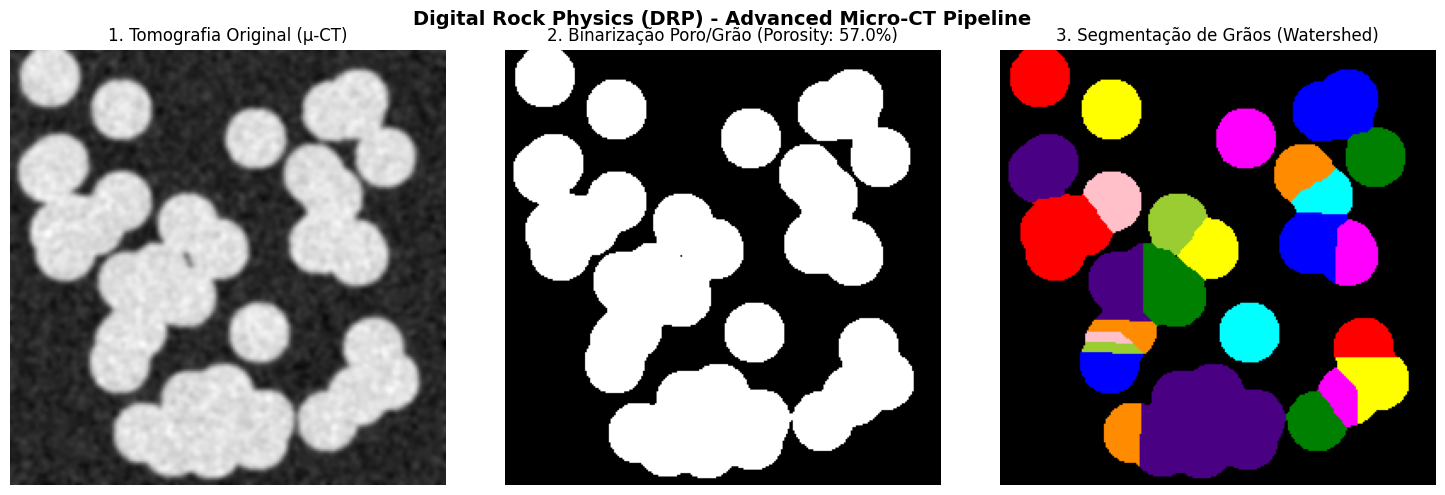

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, segmentation, color, feature, io
import os

def generate_synthetic_ct_scan(shape=(256, 256), seed=42):
    """Gera uma tomografia 2D sintética de meio poroso (grãos e poros)."""
    np.random.seed(seed)
    mask = np.zeros(shape, dtype=bool)
    num_grains = 40
    ri = np.random.randint(15, shape[0] - 15, num_grains)
    rj = np.random.randint(15, shape[1] - 15, num_grains)
    mask[ri, rj] = True

    distance = ndi.distance_transform_edt(~mask)
    grains = distance < 18

    ct_image = np.where(grains, 180.0, 60.0)
    noise = np.random.normal(0, 25.0, shape)
    ct_image = np.clip(ct_image + noise, 0, 255).astype(np.uint8)
    ct_smoothed = filters.gaussian(ct_image, sigma=1.5, preserve_range=True).astype(np.uint8)

    return ct_smoothed

def load_real_ct_scan(file_path):
    """Carrega uma imagem real de micro-CT a partir de um ficheiro (PNG/TIFF/JPG)."""
    if os.path.exists(file_path):
        img = io.imread(file_path, as_gray=True)
        # Normalizar para 0-255 e aplicar suavização gaussiana leve
        img_rescaled = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
        return filters.gaussian(img_rescaled, sigma=1.0, preserve_range=True).astype(np.uint8)
    else:
        print(f"Aviso: Ficheiro '{file_path}' não encontrado. A usar dados sintéticos...")
        return generate_synthetic_ct_scan()

def segment_grains(image):
    """Pipeline de segmentação: Otsu -> Distância Euclidiana -> Watershed."""
    # Limiarização de Otsu para binarizar poros vs grãos
    thresh = filters.threshold_otsu(image)
    binary_mask = image > thresh

    # Transformada de distância e marcadores para o Watershed
    distance = ndi.distance_transform_edt(binary_mask)
    coords = feature.peak_local_max(distance, footprint=np.ones((15, 15)), labels=binary_mask)

    local_maxi = np.zeros_like(binary_mask, dtype=bool)
    local_maxi[tuple(coords.T)] = True

    markers = ndi.label(local_maxi)[0]
    segmented_labels = segmentation.watershed(-distance, markers, mask=binary_mask)

    # Cálculo da porosidade (% de píxeis de poros em relação ao total)
    porosity = (np.sum(~binary_mask) / binary_mask.size) * 100

    return binary_mask, segmented_labels, porosity

def main():
    # Podes alterar para o caminho de uma imagem real se tiveres (ex: 'minha_rocha.png')
    real_image_path = None

    if real_image_path and os.path.exists(real_image_path):
        print(f"A carregar imagem real de micro-CT: {real_image_path}")
        ct_image = load_real_ct_scan(real_image_path)
    else:
        print("A gerar dados sintéticos avançados de Tomografia Computacional (µ-CT)...")
        ct_image = generate_synthetic_ct_scan()

    print("A processar pipeline de segmentação de grãos e cálculo de porosidade...")
    binary_mask, segmented_labels, porosity = segment_grains(ct_image)

    print(f"Processamento concluído com sucesso!")
    print(f"-> Porosidade estimada da amostra: {porosity:.2f}%")

    # Plotagem dos resultados
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(ct_image, cmap='gray')
    axes[0].set_title("1. Tomografia Original (µ-CT)")
    axes[0].axis('off')

    axes[1].imshow(binary_mask, cmap='bone')
    axes[1].set_title(f"2. Binarização Poro/Grão (Porosity: {porosity:.1f}%)")
    axes[1].axis('off')

    labeled_color = color.label2rgb(segmented_labels, bg_label=0)
    axes[2].imshow(labeled_color)
    axes[2].set_title("3. Segmentação de Grãos (Watershed)")
    axes[2].axis('off')

    plt.suptitle("Digital Rock Physics (DRP) - Advanced Micro-CT Pipeline",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()